<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Квантильная регрессия</span></h2>

В этом ноутбуке разберем квантильную регрессию &mdash; метод, позволяющий предсказывать квантили распределения целевой переменной, а также строить предсказательные интервалы для новых наблюдений.

In [1]:
import warnings
from typing import Dict, Any, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sps
import seaborn as sns
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
from sklearn.base import BaseEstimator

warnings.filterwarnings("ignore")
sns.set(style="whitegrid", font_scale=1.2, palette="Set2")

RANDOM_STATE = 42

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1</span> <span style="color:inherit;">Данные: квартиры в Москве</span>

Загрузим датасет 2024 года с данными по стоимости квартир в Москве (<a href="https://www.kaggle.com/datasets/ivan314sh/prices-of-moscow-apartments">источник</a>).

В датасете представлены данные о цене москвоской квартиры и различных характеристиках квартиры. Наша задача &mdash; предсказать цену квартиры по ее описанию.

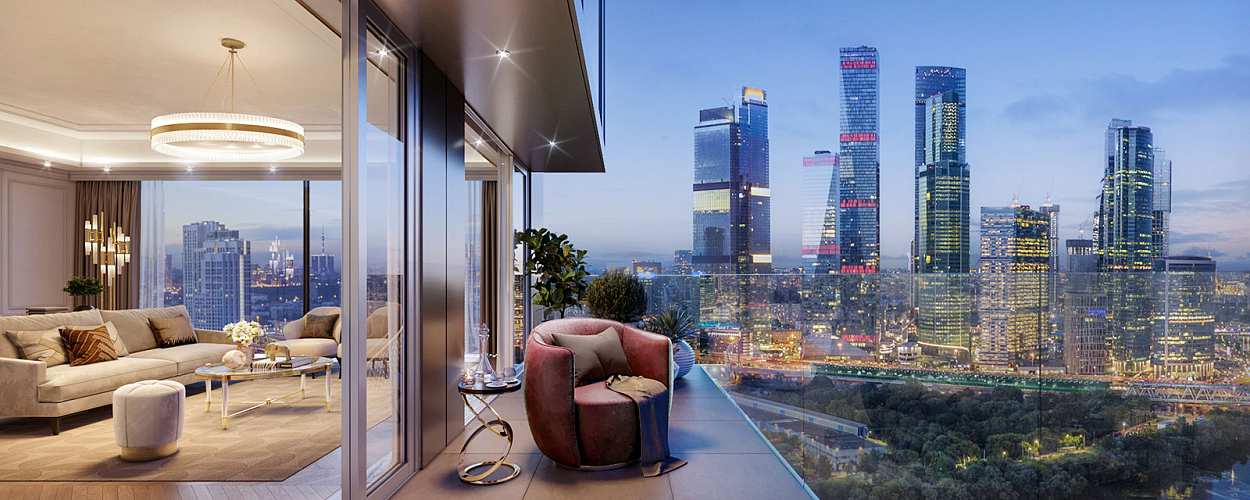

**Описание колонок**

1. **price** — цена объекта недвижимости в рублях (RUB).  
2. **min_to_metro** — примерное время (в минутах) до ближайшего метро.  
3. **region_of_moscow** — административный округ Москвы, в котором находится объект.
4. **total_area** — общая площадь объекта в квадратных метрах.  
5. **living_area** — жилая площадь объекта в квадратных метрах (помещения, предназначенные для проживания).  
6. **floor** — этаж, на котором расположен объект.  
7. **number_of_floors** — общее количество этажей в здании.  
8. **construction_year** — год постройки здания.  
9. **is_new** — бинарный признак, указывающий, является ли объект новостройкой.  
10. **is_apartments** — бинарный признак, указывающий, классифицируется ли объект как апартаменты.  
    - Значение **0** — можно официально зарегистрироваться по месту жительства.  
    - Значение **1** — регистрация невозможна (например, апартаменты без инфраструктуры). <br/>    <br/>    
11. **ceiling_height** — высота потолков в метрах.  
12. **number_of_rooms** — количество комнат (включая спальни, гостиную и т.д.).  
13. **link** — URL-ссылка на страницу объекта с подробной информацией.


In [2]:
flats = pd.read_csv("moscow_flats_dataset.csv")
flats = flats[flats.total_area < 300]  # отфильтруем слишком большие квартиры, так как их мало
flats = flats[flats.price < 600 * 1e6]  # отфильтруем слишком дорогие квартиры, так как их мало
flats["price"] = flats["price"] / 1e6  # будем измерять цены в миллионах
flats.head()

,price,min_to_metro,region_of_moscow,total_area,living_area,floor,number_of_floors,construction_year,is_new,is_apartments,ceiling_height,number_of_rooms,link
0,31.633073,24.0,ЮАО,64.2,32.4,11.0,16.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/293204033/
1,29.293000,9.0,СВАО,78.1,NaN,9.0,27.0,2022.0,1.0,0.0,NaN,2.0,https://www.cian.ru/sale/flat/294033524/
2,30.349669,5.0,ЮАО,72.4,33.6,3.0,24.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/300712697/
3,31.845511,19.0,ЮАО,69.2,NaN,2.0,12.0,2024.0,1.0,0.0,2.97,2.0,https://www.cian.ru/sale/flat/300228448/
4,38.810000,27.0,ЗАО,66.9,24.8,9.0,14.0,2023.0,1.0,0.0,3.00,2.0,https://www.cian.ru/sale/flat/299262105/


In [3]:
flats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6921 entries, 0 to 6982
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              6921 non-null   float64
 1   min_to_metro       6807 non-null   float64
 2   region_of_moscow   6853 non-null   object 
 3   total_area         6921 non-null   float64
 4   living_area        4495 non-null   float64
 5   floor              6921 non-null   float64
 6   number_of_floors   6921 non-null   float64
 7   construction_year  5732 non-null   float64
 8   is_new             6910 non-null   float64
 9   is_apartments      6910 non-null   float64
 10  ceiling_height     5032 non-null   float64
 11  number_of_rooms    6921 non-null   float64
 12  link               6921 non-null   object 
dtypes: float64(11), object(2)
memory usage: 757.0+ KB


Разделим данные на обучающую и тестовую части

In [4]:
train, test = train_test_split(flats, test_size=0.1, random_state=RANDOM_STATE)

In [5]:
X_train = train[["total_area"]]
y_train = train["price"]

X_test = test[["total_area"]]
y_test = test["price"]

Посмотрим для начала на зависимость цены квартиры от общей площади и попробуем предсказать цену только по ней.

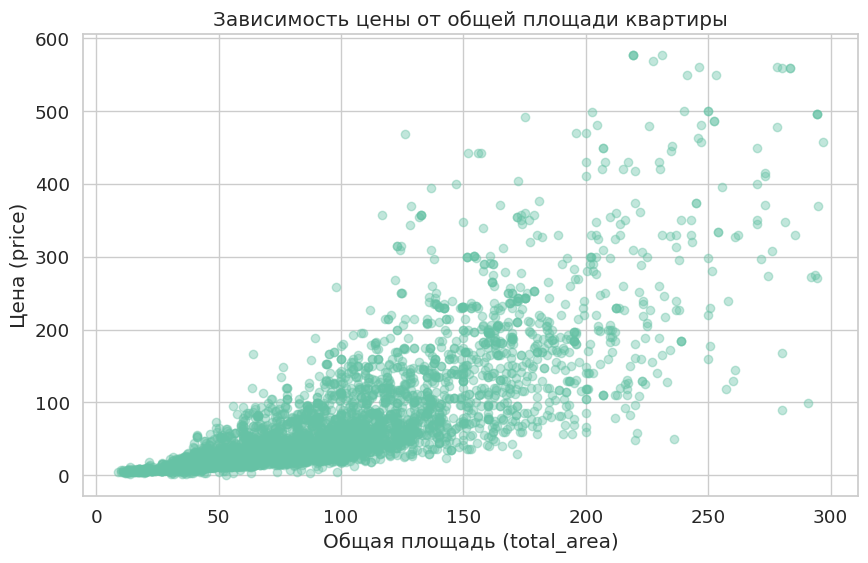

In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(train["total_area"], train["price"], alpha=0.4)
plt.xlabel("Общая площадь (total_area)")
plt.ylabel("Цена (price)")
plt.title("Зависимость цены от общей площади квартиры")
plt.show()

Определим вспомогательную функцию

In [7]:
def plot_regression_intervals(
    train_data: pd.DataFrame,
    pred_summary: pd.DataFrame,
    x_col: str,
    y_col: str,
    title: str,
) -> None:
    """
    Строит график регрессии с предиктивным интервалом.

    Args:
        train_data (pd.DataFrame): DataFrame с исходными данными для scatter plot.
        pred_summary (pd.DataFrame): DataFrame с предсказаниями, полученный из
            `.summary_frame()`. Должен содержать x_col, 'mean', 'mean_ci_lower',
            'mean_ci_upper' и колонки, указанные в pred_interval_cols.
        x_col (str): Название колонки с независимой переменной (ось X).
        y_col (str): Название колонки с зависимой переменной (ось Y).
        title (str): Заголовок графика.
    """
    plt.figure(figsize=(10, 6))

    # Исходные данные
    sns.scatterplot(
        x=x_col, y=y_col, data=train_data, alpha=0.5, color="#20b2aa", label="Обучающая выборка"
    )

    # Линия регрессии
    plt.plot(
        pred_summary[x_col],
        pred_summary["mean"],
        color="#ff2400",
        linewidth=2,
        label="Предсказания",
    )

    # Предиктивный интервал
    plt.fill_between(
        pred_summary[x_col],
        pred_summary["lower"],
        pred_summary["upper"],
        color="#8b00ff",
        alpha=0.2,
        label="95% Предикт. инт.",
    )

    plt.title(title)
    plt.xlabel(f"Общая площадь ({x_col})")
    plt.ylabel(f"Цена ({y_col})")

    plt.ylim(-50, None)
    plt.legend(loc=4, fontsize=11)
    plt.show()

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2</span> <span style="color:inherit;">Pinball Loss</span>

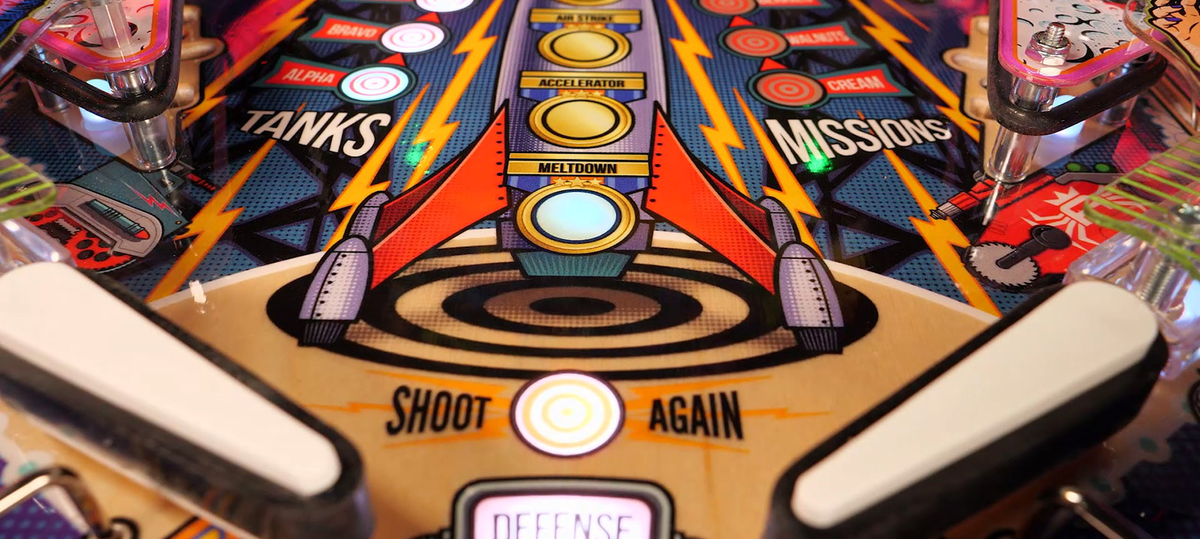

Рассмотрим простую задачу: $Y\in\mathbb{R}$, и функция потерь — **Pinball Loss уровня $\alpha\in(0,1)$**:
$$
L_\alpha(y_1, y_2) = \begin{cases}
\alpha (y_1 - y_2), & y_1 - y_2\geqslant 0,\\
(\alpha-1) (y_1 - y_2), & y_1 - y_2<0.
\end{cases}
$$

Эта функция линейна по обе стороны нуля, но с разными наклонами:
* если мы недооценили (ошибка положительная), штраф = $\alpha u$
* если переоценили (ошибка отрицательная), штраф = $(\alpha−1)u=(1−\alpha)∣u∣$

Зависимость от $\alpha$:
* если $\alpha=0.5$, наклоны равны, значит минимум находится в **медиане**;
* если $\alpha=0.9$, штраф за недооценку (слева) **в 9 раз выше**, чем за переоценку —
модель “поджимается снизу”, чтобы попадать в 90-й квантиль.

Эта форма похожа на наклонный трамплин или “рамп” в пинболе, поэтому название pinball loss закрепилось как визуальная метафора: *мячик (ошибка) "ударяется" о наклонную плоскость — и “отскакивает” с разными скоростями,
в зависимости от направления ошибки.*

In [8]:
def pinball_loss(x, alpha: float):
    """
    Вычисляет pinball loss (квантильную функцию потерь)
    для заданных ошибок x = y_true - y_pred и уровня квантиля alpha ∈ (0,1).
    """
    x = np.asarray(x)
    return np.where(x >= 0, alpha * x, (alpha - 1) * x)

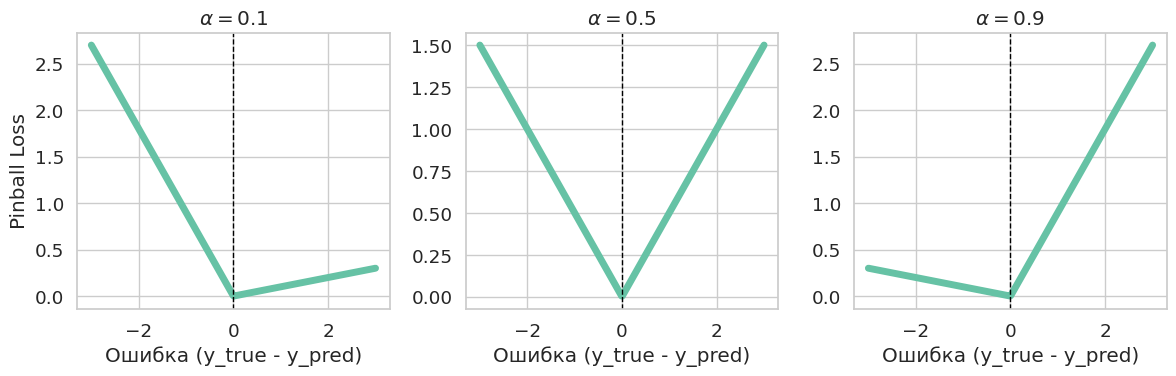

In [9]:
x = np.linspace(-3, 3, 400)
alphas = [0.1, 0.5, 0.9]

plt.figure(figsize=(12, 4))
for i, a in enumerate(alphas, 1):
    plt.subplot(1, 3, i)
    plt.plot(x, pinball_loss(x, a), lw=5)
    plt.axvline(0, color="k", lw=1, ls="--")
    plt.title(f"$\\alpha = {a}$")
    plt.xlabel("Ошибка (y_true - y_pred)")
    if i == 1:
        plt.ylabel("Pinball Loss")
plt.tight_layout()
plt.show()


Определим популяционный риск
$$
\sum_{i=1}^n L_\alpha(Y_i, \widehat{y}(x_i)) \longrightarrow \min_{\widehat{y}}.
$$


Рассмотрим теоретическое решение задачи в точке
$$
R(c) = \mathsf{E} L_\alpha(Y, с) \longrightarrow \min_{c\in\mathbb{R}}.
$$

**Утверждение.**

Любой $c\in\mathbb{R}$ такой, что $\mathsf{P}(Y\leqslant c) = \alpha$ минимизирует $R(c)$. Если функция распределения $F_Y$ непрерывна в соответствующей точке, то минимум единственный и это точная $\alpha$-квантиль $q_\alpha$.

**Доказательство.**

* Рассмотрим производную $R'(c)$ в предположении, что она существует
    $$
    \frac{d}{dc}L_\alpha(y, с) = I\{y - с<0\}-\alpha = \begin{cases}
    -\alpha, & y - с\geqslant 0,\\
    1-\alpha, & y - с<0.
    \end{cases}
    $$

    Берём математическое ожидание:
    $$
    R'(c) = \frac{d}{dc} \mathsf{E}L_\alpha(Y, с) = \mathsf{E}\left( I\{y - с<0\}-\alpha \right) = \mathsf{P}(Y\leqslant c) - \alpha.
    $$

    Следовательно, для точки экстремума $c$ выполняется $\mathsf{P}(Y\leqslant c)$, т.е. $c$ — $\alpha$-квантиль. Если $F_Y$ непрерывна в этой точке, то $R'(c)$ меняет знак с отрицательного на положительный и минимум единственен.


* Если $F_Y$ имеет атом в $q_\alpha$, то множество точек минимума — отрезок внутри этого атома. Стандартное определение квантили как $\inf\{c\:|\:F_Y(c)\geqslant\alpha\}$ подходит в качестве решения.


* Если $R(c)$ не дифференцируема в $с$, можно использовать субградиент, и тогда условие $0 ∈ \partial R(c)$ даёт тот же результат.

**Утверждение.**

Пусть $q_\alpha(x)$ &mdash; истинная $\alpha$-квантиль распределения таргета в точке $x$. Тогда решение задачи $\widehat{q}_\alpha(x)$ &mdash; **асимптотически нормальная оценка** $q_\alpha(x)$:
$$\sqrt{n} \left( \widehat{q}_\alpha(x) - q_\alpha(x) \right) \xrightarrow{d} \mathcal{N}\left(0,\ \frac{\alpha(1-\alpha)}{w_x\: p_x(q_\alpha(x))} \right),$$
где $p_x(y)$ &mdash; плотность распределения таргета в точке $x$, $w_x$ &mdash; «эффективный» частотный вес наблюдений в окрестности точки $x$ (в бустинге определяется через среднюю долю объектов в листе по деревьям).

## <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">3</span> <span style="color:inherit;">Построение интервалов</span>

Зафиксируем уровень значимости

In [10]:
alpha = 0.05

Обучим **три модели** CatBoost:
* обычная модель для предсказания среднего / медианы
* квантильная регрессия для предсказания $\alpha/2$-квантили распределения таргета в точке $x$
* квантильная регрессия для предсказания $1-\alpha/2$-квантили распределения таргета в точке $x$

In [11]:
iterations = 500

models = {
    "mean": CatBoostRegressor(loss_function="RMSE", iterations=iterations, verbose=0).fit(
        X_train, y_train
    ),
    "lower": CatBoostRegressor(
        loss_function=f"Quantile:alpha={alpha/2}", iterations=iterations, verbose=0
    ).fit(X_train, y_train),
    "upper": CatBoostRegressor(
        loss_function=f"Quantile:alpha={1-alpha/2}", iterations=iterations, verbose=0
    ).fit(X_train, y_train),
}

In [12]:
def predict(models: Dict[str, BaseEstimator], X_test: pd.DataFrame) -> pd.DataFrame:
    """Генерирует предсказания для набора моделей.

    Args:
        models (Dict[str, BaseEstimator]): Словарь с обученными моделями {название: модель}.
        X_test (pd.DataFrame): Тестовые данные для предсказания.

    Returns:
        pd.DataFrame: DataFrame с предсказаниями от каждой модели в отдельном столбце.
    """
    predicted_values = pd.DataFrame(index=X_test.index)
    for key in models:
        predicted_values[key] = models[key].predict(X_test)
    return predicted_values


def estimate_coverage(y_test: Union[pd.Series, np.ndarray], y_preds: pd.DataFrame) -> float:
    """Оценивает покрытие предсказательного интервала.

    Args:
        y_test (Union[pd.Series, np.ndarray]): Истинные значения целевой переменной.
        y_preds (pd.DataFrame): DataFrame с предсказанными границами интервала ('lower', 'upper').

    Returns:
        float: Значение покрытия (доля истинных значений, попавших в интервал).
    """
    y_test = np.array(y_test)
    y_lower = np.array(y_preds["lower"])
    y_upper = np.array(y_preds["upper"])

    coverage = np.mean((y_test >= y_lower) & (y_test <= y_upper))
    return float(coverage)

Получим предсказания на тестовой выборке и оценим долю покрытия интервалом фактических значений таргета

In [13]:
y_preds = predict(models, X_test)
y_preds.head()

,mean,lower,upper
468,22.650253,11.241067,51.591419
2843,17.142920,7.554157,31.155573
800,36.608066,15.472183,83.321893
3417,11.470210,7.551286,20.118100
3534,10.757732,7.079090,17.706979


In [14]:
y_preds = predict(models, X_test)
coverage = estimate_coverage(y_test, y_preds)
print(f"Покрытие 95% PI: {coverage:.3f}")

Покрытие 95% PI: 0.949


Создадим сетку значений для `total_area` и получим предсказания среднего и квантилей

In [15]:
totsp_grid = np.linspace(train["total_area"].min(), train["total_area"].max(), 100)
grid_data = pd.DataFrame({"total_area": totsp_grid})

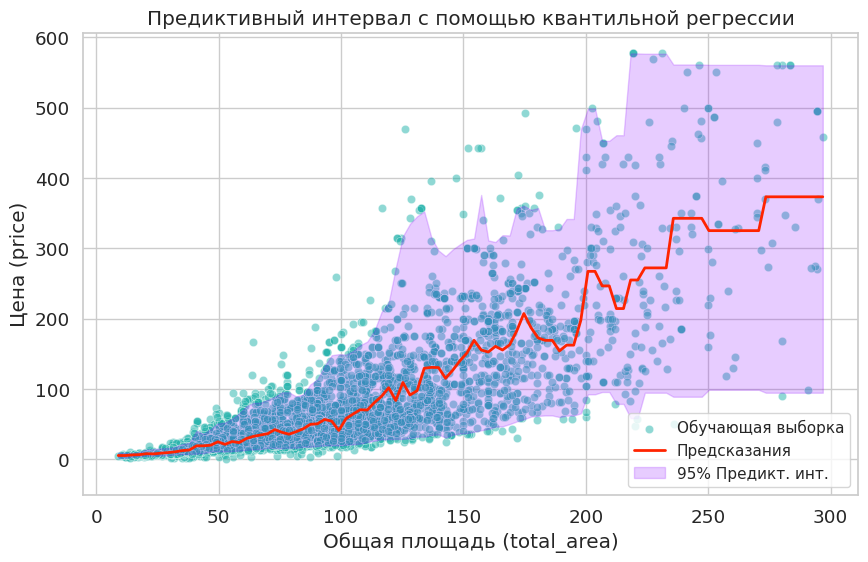

In [16]:
plot_data = pd.concat([grid_data, predict(models, grid_data)], axis=1)

plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Предиктивный интервал с помощью квантильной регрессии",
)

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4</span> <span style="color:inherit;">Монотонные предсказания</span>

**Априорное знание или бизнес-требование:** предсказания должны быть монотонными по одному или нескольким признакам.

Монотонные ограничения позволяют учитывать известные зависимости между признаками и целевой переменной. Например, при прогнозировании цены квартиры хотелось бы, чтобы с увеличением площади предсказанная цена не уменьшалась при прочих равных. 
Это помогает 
* избежать нелогичных предсказаний
* учитывать предметные знания
* получать более интерпретируемые результаты.

*Примеры:*
* зависимости физических величин;
* при увеличении населения должен быть рост трафика.
	
**Принцип построения**
	
* Устанавливаем для листьев ограничение на множество значений. Изначально для корня ограничение --- вся прямая $\mathbb{R}$
		
* Пусть для текущего узла установлено ограничение $(x, y) \subset \mathbb{R}$.
		
* При разбиении по признаку, для которого должна быть монотонность, устанавливаем ограничение
     * в левом поддереве $(x, z)$,
     * в правом поддереве $(z, y)$.
		
* Условие монотонности выполняется в каждом дереве, это проще для реализации.
		
Если сразу поставили сильно большую разницу в предсказании, то следующими деревьями не сможем добиться хорошего монотонного предсказания. Для решения этой проблемы CatBoost при обучении нового дерева предсказания предыдущих сжимает, домножая на понижающий коэффициент.

В CatBoost требование монотонности можно задать с помощью опции `monotone_constraints` &mdash; маска 0 и 1 по количеству признаков, где 1 означает требование на монотонность по этому признаку.



<div style="box-sizing:border-box;max-width:100%;margin:14px 0 0;padding:0;border:1px solid rgba(199,50,78,0.20);border-bottom:0;border-radius:12px 12px 0 0;overflow:hidden;color:inherit;"><span style="display:inline-block;padding:4px 11px;border-radius:4px 12px 12px 4px;background:linear-gradient(135deg,#D4470E,#C7324E,#B316B8);color:white;font-size:10.5px;font-weight:800;letter-spacing:0.06em;text-transform:uppercase;white-space:nowrap;">Вопрос</span></div>

<div style="box-sizing:border-box;max-width:100%;padding:10px 14px 13px;border-left:1px solid rgba(199,50,78,0.20);border-right:1px solid rgba(199,50,78,0.20);border-bottom:1px solid rgba(199,50,78,0.20);border-radius:0 0 12px 12px;margin-bottom:8px;">

Для каких моделей из наших трёх разумно требовать мононность предсказания по площади квартиры?

</div>

<details style="box-sizing:border-box;max-width:100%;margin:0 0 18px;padding:8px 14px 10px;border:1px solid rgba(199,50,78,0.20);border-radius:10px;color:inherit;">

<summary style="cursor:pointer;color:inherit;font-size:13px;font-weight:750;text-decoration:underline;text-decoration-color:#C7324E;text-decoration-thickness:1.5px;text-underline-offset:3px;">Показать ответ</summary>

Монотонность разумно требовать только от первой модели, которая предсказывает среднюю цену квартиры: при увеличении площади средняя цена не должна уменьшаться.
Для моделей, предсказывающих квантили, такая зависимость не всегда оправданна. Например, с увеличением площади разброс цен может уменьшаться, поэтому верхняя граница предсказательного интервала может стать ниже, даже если средняя цена выросла.

В частности, стандартные методы позволяют задавать ограничения монотонности для обычной регрессии, но не всегда для квантильной.

</details>


Поэтому поступим следующим образом:
1) Обучаем модель для предсказания среднего $\mu(x) = \mathsf{E} (Y\mid X=x)$ с ограничением монотонности.

2) Обучаем модели для предсказания квантилей остатков.

   
    Для каждого объекта обучающей выборки вычисляем остаток:
    $$ r_i=y_i-\widehat\mu(x_i).$$

    Затем обучаем две квантильные модели, которые предсказывают нижний и верхний квантили распределения остатков:

    $$ \widehat q_{\alpha/2}(x), \qquad \widehat{q}_{1-\alpha/2}(x). $$

    Для обучения используем Pinball Loss с соответствующими уровнями квантилей.

3) Получаем предсказания всех трёх моделей.

    Для новой квартиры с признаками $x_0$ получаем:

    - $\widehat\mu(x_0)$ &mdash; предсказанную среднюю цену;
    - $\widehat q_{\alpha/2}(x_0)$ &mdash; нижний квантиль остатков;
    - $\widehat q_{1-\alpha/2}(x_0)$ &mdash; верхний квантиль остатков.

4) Восстанавливаем границы предсказательного интервала.
    $$\left( \widehat\mu(x_0)+\widehat q_{\alpha/2}(x_0), \; \widehat\mu(x_0)+\widehat q_{1-\alpha/2}(x_0) \right).$$

Таким образом, разделяем задачу на две части: первая модель отвечает за монотонный прогноз средней цены, а две остальные &mdash; за оценку разброса цен относительно этого прогноза.


In [17]:
iterations = 500

models = {
    "mean": CatBoostRegressor(
        loss_function="RMSE", monotone_constraints=[1], iterations=iterations, verbose=0
    ).fit(X_train, y_train),
}
resid = y_train - models["mean"].predict(X_train)

models["lower"] = CatBoostRegressor(
    loss_function=f"Quantile:alpha={alpha/2}", iterations=iterations, verbose=0
).fit(X_train, resid)
models["upper"] = CatBoostRegressor(
    loss_function=f"Quantile:alpha={1-alpha/2}", iterations=iterations, verbose=0
).fit(X_train, resid)

Поправим функцию предсказания

In [18]:
def predict(models: Dict[str, BaseEstimator], X_test: pd.DataFrame) -> pd.DataFrame:
    """Генерирует предсказания для набора моделей.

    Args:
        models (Dict[str, BaseEstimator]): Словарь с обученными моделями {название: модель}.
        X_test (pd.DataFrame): Тестовые данные для предсказания.

    Returns:
        pd.DataFrame: DataFrame с предсказаниями от каждой модели в отдельном столбце.
    """
    predicted_values = pd.DataFrame()
    predicted_values["mean"] = models["mean"].predict(X_test)
    predicted_values["lower"] = predicted_values["mean"] + models["lower"].predict(X_test)
    predicted_values["upper"] = predicted_values["mean"] + models["upper"].predict(X_test)
    return predicted_values

In [19]:
y_preds = predict(models, X_test)
coverage = estimate_coverage(y_test, y_preds)
print(f"Покрытие 95% PI: {coverage:.3f}")

Покрытие 95% PI: 0.949


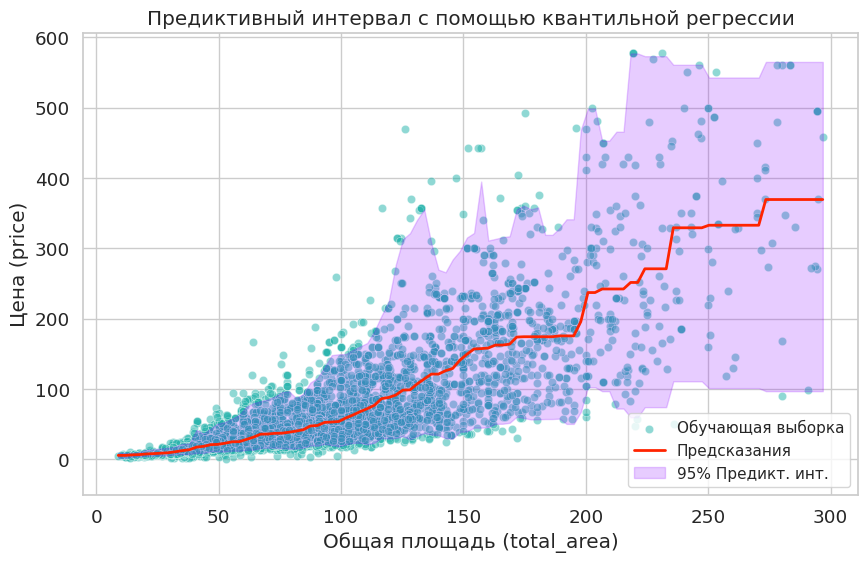

In [20]:
plot_data = pd.concat([grid_data, predict(models, grid_data)], axis=1)

plot_regression_intervals(
    train_data=train,
    pred_summary=plot_data,
    x_col="total_area",
    y_col="price",
    title="Предиктивный интервал с помощью квантильной регрессии",
)

Мы получили эффективный инструмент построения предсказательных интервалов в случае нелинейных зависимостей, который также позволяет получать монотонные предсказания среднего.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>